# Sovereign curves: Treasury yield curves and rate risk from FedInvest prices

The pipeline fetches the Treasury's FedInvest end-of-day prices every weekday, loads them into a
Parquet lake with accrued interest and the dirty price, and builds three curves a day: FIA's exact
bootstrap, a Svensson fit of our own, and the Fed Board's GSW curve as the answer key. Every bill,
note and bond then gets its pricing error against each curve and its risk: DV01, modified
duration, convexity, key-rate DV01s and carry.

South Africa runs through the same code as a second market: the National Treasury's fixed-rate bond
auctions since April 2010, priced with the JSE bond pricing formula, a curve per auction from FIA's
bootstrap, and its 10-year point against the OECD's and the IMF's monthly South African bond yields
(sections 9 to 11).

This notebook reads the committed sample (October 2026, and 15 September 2008 and 16 March 2020
for the truth check, and the Treasury's parsed rows in `data/sa`) after `local-development/run_local.py` has run it through the same fetch
stand-in, Glue loader and ECS engine code. It builds `_localrun/` first if it is not there.

In [1]:
import datetime as dt
import gzip
import json
import sys
import warnings
from pathlib import Path

warnings.simplefilter("ignore", SyntaxWarning)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT = Path.cwd()
for p in (PROJECT, PROJECT / "local-development", PROJECT / "glue-pythonshell", PROJECT / "ecs", PROJECT / "lambda-functions"):
    sys.path.insert(0, str(p))
RUN = PROJECT / "_localrun"
if not all((RUN / "lake-bucket" / t).exists() for t in ("risk", "sa_curves")):
    import run_local
    run_local.main([])

import app
import load
import truth_check
from bond_analytics import dates, truth
from bond_analytics.fedinvest import parse_prices

pd.set_option("display.width", 160)
RAW, LAKE = RUN / "raw-bucket", load.FolderStore(RUN / "lake-bucket")

def lake_table(name):
    frames = [load.from_parquet(LAKE.get(k)) for k in LAKE.list(name + "/")]
    return pd.concat(frames, ignore_index=True)

def page(day):
    path = RAW / "raw" / "fedinvest" / f"date={day}" / "prices.html"
    return parse_prices(path.read_text(encoding="latin-1"), dt.date.fromisoformat(day))

prices, curves, params, errors, risk = (lake_table(t) for t in ("prices", "curves", "curve_params", "fit_errors", "risk"))
print(f"{prices.price_date.nunique()} price dates, {len(prices):,} security-days; "
      f"{len(curves):,} curve points, {len(errors):,} fit errors, {len(risk):,} risk rows")

23 price dates, 10,354 security-days; 768 curve points, 24,966 fit errors, 8,991 risk rows


## 1. Settlement is T+1, and the bills say so

FedInvest's price for a date is for settlement the next business day. A clean price cannot show
that: it is continuous across a coupon date whichever convention it was struck on. The bills can,
because a bill a few days from maturity is priced off a handful of days, and counting one day too
many collapses its yield. On Friday 30 October 2026, counting from the price date:

In [2]:
rows = []
for r in page("2026-10-30"):
    if r["security_type"] != "MARKET BASED BILL":
        continue
    maturity = dt.datetime.strptime(r["maturity_date"], "%m/%d/%Y").date()
    price = float(r["end_of_day"])
    for label, settle in (("T+0", dt.date(2026, 10, 30)), ("T+1", dates.settlement_date(dt.date(2026, 10, 30)))):
        days = (maturity - settle).days
        rows.append({"maturity": maturity, "settles": label, "days": days, "discount yield %": round((100 - price) / 100 * 360 / days * 100, 2)})
bills = pd.DataFrame(rows)
bills.pivot(index="maturity", columns="settles", values="discount yield %").head(6)

settles,T+0,T+1
maturity,,
2026-11-03,0.95,3.82
2026-11-05,1.94,3.88
2026-11-10,2.82,3.88
2026-11-12,2.98,3.88
2026-11-17,3.23,3.88
2026-11-19,3.30,3.88


Counted from Monday 2 November, the six shortest bills yield 3.82% and then 3.88%, flat; counted
from the price date, their yields climb from under 1%, because three days that are not in the price
are counted as if they were.

The coupon date then checks the accrued interest. Five notes between one and ten years paid a
coupon on 15 October 2026. With T+1, the trade on the 14th settles on the coupon date, so its
dirty price drops by the coupon that day, and dirty price plus the coupon paid runs on as the
other notes do:

In [3]:
frames = []
for d in ("2026-10-13", "2026-10-14", "2026-10-15", "2026-10-16"):
    q = load.from_parquet(LAKE.get(f"prices/date={d}/prices.parquet"))
    frames.append(q[(q.kind == "note") & q.dirty.notna()])
notes = pd.concat(frames)
notes["payer"] = notes.maturity.map(lambda m: m.day == 15 and m.month in (4, 10)) & (notes.maturity > dt.date(2026, 10, 15))
notes = notes[(notes.years > 1) & (notes.years < 10)]
wide = {c: notes.pivot(index="cusip", columns="price_date", values=c) for c in ("dirty", "clean")}
payer = notes.groupby("cusip").payer.first()
half = notes.groupby("cusip").coupon.first() / 2
days = sorted(notes.price_date.unique())
out = []
for a, b in zip(days, days[1:]):
    dd = wide["dirty"][b] - wide["dirty"][a]
    paid = half if str(a) == "2026-10-13" else 0
    out.append({"from": a, "to": b, "payers' dirty change": dd[payer].median(), "payers' dirty + coupon paid": (dd + paid)[payer].median(),
                "other notes' dirty change": dd[~payer].median(), "payers' clean change": (wide["clean"][b] - wide["clean"][a])[payer].median()})
print(f"{int(payer.sum())} payers, median half coupon {half[payer].median():.4f}; {int((~payer).sum())} other notes")
pd.DataFrame(out).round(4)

5 payers, median half coupon 1.9375; 186 other notes


,from,to,payers' dirty change,payers' dirty + coupon paid,other notes' dirty change,payers' clean change
0,2026-10-13,2026-10-14,-1.8960,-0.0210,0.0096,-0.0312
1,2026-10-14,2026-10-15,0.1034,0.1034,0.1995,0.0938
2,2026-10-15,2026-10-16,0.1241,0.1241,0.1235,0.0938


## 2. The truth check: every note and bond off GSW's curve

GSW's parameters for the day, through FIA's `relative_bond.price`, against FedInvest's clean price
plus accrued at T+1. Positive basis points mean the bond is cheap to the curve. Anything within three
months of maturity is left out, as GSW leave it out, and so are callable bonds.

In [4]:
TC = truth_check.run(RAW, truth_check.DATES)
rows = truth.table_rows(TC)
for d, day in rows.groupby("price_date"):
    display(truth.summarise(day, ["bucket", "kind"]).rename_axis(index=[str(d), "kind"]))

n  mean_price  mae_price  mean_bp  mae_bp
2008-09-15 kind                                            
0-1y       bill  17      -0.065      0.075    -20.8    22.0
           note  23      -0.001      0.049     -3.5     8.9
1-2y       note  29      -0.050      0.081     -2.7     5.2
2-3y       note  13      -0.087      0.088     -3.6     3.6
3-5y       note  30       0.184      0.185      4.7     4.8
5-7y       bond   2       0.301      0.301      4.0     4.0
           note   8      -0.627      0.627    -10.5    10.5
7-10y      bond   7       0.518      0.518      5.8     5.8
           note  12      -0.951      0.951    -12.3    12.3
10-15y     bond  14       0.363      0.387      3.1     3.3
15-20y     bond  10      -0.252      0.252     -1.7     1.7
20-25y     bond   5      -0.027      0.076     -0.2     0.5
25-30y     bond   5       0.157      0.157      0.9     0.9

n  mean_price  mae_price  mean_bp  mae_bp
2020-03-16 kind                                            
0-1y       bill  19      -0.216      0.216    -46.8    46.8
           bond   2       0.004      0.051      3.9     8.9
           note  39       0.012      0.051      2.4     8.8
1-2y       bond   3       0.073      0.107      4.2     7.0
           note  50      -0.013      0.038     -0.6     2.4
2-3y       bond   3       0.105      0.105      3.6     3.6
           note  37      -0.037      0.054     -1.6     2.2
3-5y       bond   3      -0.014      0.092      0.1     2.0
           note  54      -0.055      0.113     -1.0     2.6
5-7y       bond   5       0.227      0.227      3.2     3.2
           note  32       0.034      0.084      0.5     1.4
7-10y      bond   6       0.211      0.211      2.1     2.1
           note  12      -0.060      0.189     -0.7     2.1
10-15y     bond   2       0.074      0.074      0.6     0.6
15-20y     bond  10      -1.142      1.142     -5.4     5.4
20-25y     bond  20       1.040      1.080      4.3     4.4
25-30y     bond  20      -0.912      1.212     -3.3     4.5

n  mean_price  mae_price  mean_bp  mae_bp
2026-10-23 kind                                            
0-1y       bill  23      -0.014      0.015     -2.4     2.6
           bond   2       0.107      0.107     21.0    21.0
           note  38       0.004      0.011      0.6     2.0
1-2y       bond   2       0.219      0.219     17.3    17.3
           note  51       0.017      0.018      1.4     1.5
2-3y       bond   3       0.080      0.080      3.7     3.7
           note  40      -0.005      0.013     -0.2     0.6
3-5y       bond   2       0.045      0.083      1.4     2.4
           note  55       0.006      0.020      0.1     0.6
5-7y       note  32       0.104      0.104      2.1     2.1
7-10y      bond   1      -1.013      1.013    -13.9    13.9
           note  12       0.103      0.126      1.6     2.0
10-15y     bond  21      -0.396      0.396     -4.7     4.7
15-20y     bond  40       0.281      0.281      2.8     2.8
20-25y     bond  20       0.027      0.137      0.2     1.5
25-30y     bond  20      -0.247      0.247     -2.0     2.0

Pooled over every maturity, run status would compare unlike with unlike: every note under a year is
off-the-run, and short yields are noisy. Inside each bucket that holds an on-the-run issue the
comparison is like with like. In March 2020 the on-the-run issue is the worst-priced in all six
buckets that hold one; on 23 October 2026 the three differ by a basis point or two either way.

In [5]:
nb = rows[rows.kind != "bill"]
truth.run_status_within_buckets(nb)

run                on-the-run  first off-the-run  off-the-run  n off-the-run
price_date bucket                                                           
2008-09-15 1-2y           3.2                3.9          5.5             25
           3-5y           0.1                2.7          5.0             28
           7-10y         19.6               17.9          8.8             17
           25-30y         0.4                1.4          0.8              3
2020-03-16 1-2y          15.3                5.8          2.4             51
           2-3y           8.7                3.4          2.1             38
           3-5y          11.6                6.2          2.4             55
           5-7y           2.4                0.1          1.6             35
           7-10y          6.9                4.1          1.7             16
           25-30y        16.5               12.0          3.4             18
2026-10-23 1-2y           0.6                0.2          2.1             51
           2-3y           1.6                0.3          0.8             41
           3-5y           0.5                0.5          0.7             55
           5-7y           1.5                1.4          2.1             30
           7-10y          1.3                0.6          3.2             11
           15-20y         2.0                2.8          2.8             38
           25-30y         2.9                3.1          1.8             18

Three regressions guard the mechanics. A wrong accrued shows as a slope on the share of the coupon
period elapsed, near half a coupon; a wrong time axis as a slope on maturity; wrong cash flows as
a price error that grows with the coupon. The coupon slope is taken within buckets with on-the-run
issues left out, then again with the years since issue beside it, to tell a coupon effect from
old-bond liquidity.

In [6]:
checks = []
for d, day in nb[nb.coupon > 0].groupby("price_date"):
    elapsed = day.accrued / (day.coupon / 2)
    day = day.assign(age=[(pd.Timestamp(d) - pd.Timestamp(i)).days / 365.25 if i is not None and i == i else np.nan for i in day.issue_date])
    bp, px, both = truth.coupon_slope(day, "error_bp"), truth.coupon_slope(day, "error_price"), truth.coupon_slope(day, "error_bp", extra=("age",))
    checks.append({"price_date": d, "half coupon (median)": (day.coupon / 2).median(),
                   "slope on period elapsed": np.polyfit(elapsed, day.error_price, 1)[0],
                   "slope per 10y of maturity": np.polyfit(day.years, day.error_price, 1)[0] * 10,
                   "price per coupon point": f"{px['slope']:+.3f} ({px['se']:.3f})",
                   "bp per coupon point": f"{bp['slope']:+.2f} ({bp['se']:.2f})",
                   "bp per coupon point, age held": f"{both['slope']:+.2f} ({both['se']:.2f})",
                   "bp per year since issue": f"{both['slope_age']:+.2f} ({both['se_age']:.2f})"})
pd.DataFrame(checks).set_index("price_date").round(3).T

price_date,2008-09-15,2020-03-16,2026-10-23
half coupon (median),2.25,1.125,1.938
slope on period elapsed,0.04,0.068,0.027
slope per 10y of maturity,-0.006,-0.097,-0.018
price per coupon point,+0.165 (0.016),+0.012 (0.016),+0.005 (0.006)
bp per coupon point,+2.25 (0.40),+0.54 (0.21),+0.56 (0.13)
"bp per coupon point, age held",+0.95 (0.69),-0.11 (0.47),+0.47 (0.13)
bp per year since issue,+0.45 (0.20),+0.16 (0.10),+0.18 (0.03)


## 3. A quote the loader flags and keeps

The largest pricing error on 23 October 2026 is a 6.5% bond three weeks from maturity. Two notes
mature the same day, and the bills price all three without a fitted curve:

In [7]:
p23 = load.from_parquet(LAKE.get("prices/date=2026-10-23/prices.parquet"))
same_day = p23[p23.maturity == dt.date(2026, 11, 15)][["cusip", "kind", "coupon", "buy", "sell", "clean", "accrued", "dirty", "bill_curve_gap", "neighbour_gap_ticks", "quality_flags"]]
same_day.assign(gap_32nds=same_day.bill_curve_gap * 32).round(4)

,cusip,kind,coupon,buy,sell,clean,accrued,dirty,bill_curve_gap,neighbour_gap_ticks,quality_flags,gap_32nds
52,91282CJK8,note,4.625,0.0,100.0312,100.0000,2.0611,102.0611,-0.0301,-0.4401,,-0.9621
53,912828U24,note,2.000,0.0,99.8750,99.8750,0.8913,100.7663,-0.0152,0.1589,,-0.4877
290,912810EY0,bond,6.500,0.0,99.9688,99.9062,2.8967,102.8030,-0.2237,-6.6361,off_neighbours,-7.1581


The notes are within a 32nd of the bills, which is the quote's own rounding; the bond is seven 32nds
low. The loader keeps the price as quoted and adds `off_neighbours`, which fires when a quote sits
more than four 32nds from the median gap of the notes and bonds maturing within 31 days of it.
Over the sample:

In [8]:
checked = prices.neighbour_gap_ticks.dropna()
flagged = prices[prices.quality_flags.str.contains("off_neighbours")]
print(f"{len(checked):,} quotes checked against their neighbours: median |gap| {checked.abs().median():.2f}, "
      f"90th percentile {checked.abs().quantile(0.9):.2f} 32nds; {len(flagged)} flagged")
flagged.groupby(["cusip", "coupon", "maturity"]).agg(days=("price_date", "size"), median_32nds=("neighbour_gap_ticks", "median")).round(2)

1,188 quotes checked against their neighbours: median |gap| 0.40, 90th percentile 1.42 32nds; 41 flagged


,,,days,median_32nds
cusip,coupon,maturity,,
912810EY0,6.500,2026-11-15,18,-6.14
912810EZ7,6.625,2027-02-15,8,-4.85
912810FA1,6.375,2027-08-15,14,-5.40
9128285G1,2.875,2020-10-31,1,-4.76


## 4. Three curves

FIA's bootstrap goes through 40 to 45 bonds a day exactly, one per maturity bucket, bills under a year and
off-the-run notes and bonds beyond. Our Svensson fit minimises duration-weighted price errors over
the notes and bonds GSW would use. GSW's own curve is the third. On 23 October 2026:

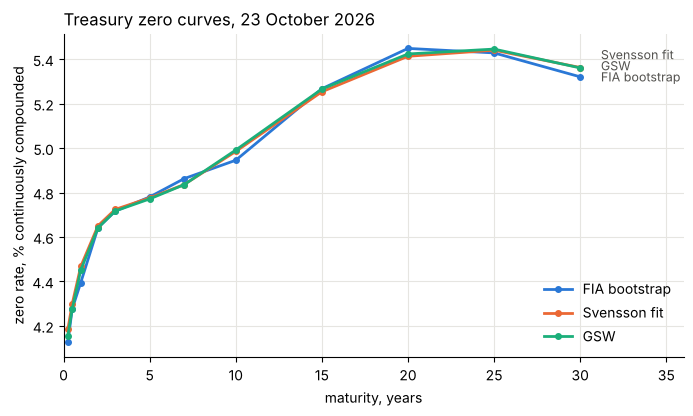

tenor,0.25,0.50,1.00,2.00,3.00,5.00,7.00,10.00,15.00,20.00,25.00,30.00
curve,,,,,,,,,,,,
"fia_bootstrap - GSW, bp",-3.0,0.0,-5.7,-0.0,-0.1,0.9,2.7,-4.6,0.2,2.5,-1.7,-4.0
"svensson - GSW, bp",2.8,2.3,1.6,0.9,0.7,0.5,0.1,-0.6,-1.2,-1.0,-0.5,0.2


In [9]:
c = curves[curves.price_date == dt.date(2026, 10, 23)].pivot(index="tenor", columns="curve", values="zero_rate")
SERIES = {"fia_bootstrap": ("#2a78d6", "FIA bootstrap"), "svensson": ("#eb6834", "Svensson fit"), "gsw": ("#1baf7a", "GSW")}
fig, ax = plt.subplots(figsize=(8, 4.2))
ends, gap = {}, 0.05  # direct labels at the 30-year end, nudged apart where the curves meet
for name in sorted(SERIES, key=lambda n: c[n].iloc[-1]):
    y = c[name].iloc[-1]
    ends[name] = max(y, max(ends.values(), default=-1e9) + gap)
for name, (colour, label) in SERIES.items():
    ax.plot(c.index, c[name], color=colour, lw=2, marker="o", ms=4, label=label)
    ax.annotate(label, (c.index[-1], c[name].iloc[-1]), xytext=(31.2, ends[name]), textcoords="data", va="center", fontsize=9, color="#52514e")
ax.set_xlabel("maturity, years"); ax.set_ylabel("zero rate, % continuously compounded")
ax.set_title("Treasury zero curves, 23 October 2026", loc="left")
ax.grid(color="#e6e5e1", lw=0.8); ax.spines[["top", "right"]].set_visible(False); ax.set_xlim(0, 36)
ax.legend(frameon=False, loc="lower right")
plt.show()
((c[["fia_bootstrap", "svensson"]].sub(c["gsw"], axis=0)) * 100).round(1).T.rename(index=lambda s: s + " - GSW, bp")

Every Svensson fit is recorded with the parameters that ended on a bound of the search. In October
2026 that is `beta0`, the long-run level, at zero, which is where GSW's own fit puts it (5.5e-13 on
the 23rd); in September 2008 it is `beta3`, because the two humps' decay parameters were nearly
equal and their loadings trade off.

In [10]:
sv = params[params.curve == "svensson"].sort_values("price_date")
print(sv.params_at_bound.replace("", "none").value_counts().to_string())
both = params[params.curve.isin(["svensson", "gsw"]) & params.price_date.isin([dt.date(2008, 9, 15), dt.date(2020, 3, 16), dt.date(2026, 10, 23)])]
both.set_index(["price_date", "curve"])[["beta0", "beta1", "beta2", "beta3", "tau1", "tau2", "rmse_bp", "n_bonds", "params_at_bound"]].round(3)

params_at_bound
beta0    21
beta3     1
none      1


beta0  beta1   beta2   beta3   tau1    tau2  rmse_bp  n_bonds params_at_bound
price_date curve                                                                                  
2008-09-15 svensson  2.541 -1.037 -54.974  60.000  4.690   5.210    7.651    148.0           beta3
           gsw       3.047 -1.431 -25.314  28.559  3.983   4.939      NaN      NaN                
2020-03-16 svensson  3.094 -2.060  -3.015  -5.513  1.385   7.419    5.570    286.0                
           gsw       3.226 -2.284  -2.884  -5.707  1.546   7.877      NaN      NaN                
2026-10-23 svensson  0.000  4.046   4.465  16.115  1.964  16.046    3.139    301.0           beta0
           gsw       0.000  4.010   4.512  16.154  1.923  15.833      NaN      NaN

## 5. Fit errors against FedInvest

Notes and bonds three months or more from maturity, every sample date, mean absolute error by
curve. The bootstrap is exact on its own knots and interpolates between them; the two Svensson
curves are smooth and miss everything a little.

In [11]:
fe = errors[(errors.years >= 0.25) & ~errors.callable & errors.kind.isin(["note", "bond"])]
fe.groupby("curve").agg(security_days=("error_bp", "size"), mae_bp=("error_bp", lambda s: s.abs().mean()),
                        mae_price=("error_price", lambda s: s.abs().mean()), knots_or_fit=("in_fit", "sum")).round(3)

,security_days,mae_bp,mae_price,knots_or_fit
curve,,,,
fia_bootstrap,7573,2.255,0.047,865
gsw,5880,2.296,0.120,5251
svensson,7573,2.266,0.123,6754


## 6. Risk

On the fitted curve shifted by each bond's own z-spread, so it reprices the bond exactly, a
one-basis-point bump at each key tenor in the shape of a triangle gives the key-rate DV01s. The
triangles add to one, so the five add to the curve DV01 of a parallel shift. DV01, modified
duration and convexity are on the bond's own semiannual yield, through FIA's `YTM`,
`create_flat_curve`, `dollar`, `duration` and `convexity`. Carry is the coupon income over 30
days less financing the dirty price at the day's funding rate. The on-the-run issues on
30 October 2026, per 100 face:

In [12]:
k = [c for c in risk.columns if c.startswith("krd_")]
rel = ((risk[k].sum(axis=1) - risk.curve_dv01).abs() / risk.curve_dv01.abs()).max()
print(f"{len(risk):,} security-days; largest |sum of key rates - curve DV01| relative to it: {rel:.1e}")
f30 = params[(params.curve == "svensson") & (params.price_date == dt.date(2026, 10, 30))].iloc[0]
print(f"funding on 30 October 2026: {f30.funding_rate:.2f}% ({f30.funding_source})")
otr = risk[(risk.price_date == dt.date(2026, 10, 30)) & (risk.run == "on-the-run")].sort_values("years")
otr[["cusip", "coupon", "maturity", "ytm", "dv01", "modified_duration", "convexity", "z_spread_bp", "carry_30d"] + k].round(4)

8,991 security-days; largest |sum of key rates - curve DV01| relative to it: 6.7e-07
funding on 30 October 2026: 3.95% (SOFR)


,cusip,coupon,maturity,ytm,dv01,modified_duration,convexity,z_spread_bp,carry_30d,krd_2y,krd_5y,krd_10y,krd_20y,krd_30y
8736,91282CRP8,4.750,2028-09-30,4.5712,0.0181,1.8013,4.1977,-2.0006,0.0599,0.0186,0.0000,0.0000,0.0000,0.0000
8779,91282CRQ6,4.875,2029-10-15,4.6437,0.0274,2.7160,8.9803,-2.1376,0.0698,0.0196,0.0085,0.0000,0.0000,0.0000
8834,91282CRN3,5.000,2031-09-30,4.7183,0.0437,4.2969,21.8843,-0.8992,0.0774,0.0041,0.0406,0.0000,0.0000,0.0000
8866,91282CRM5,5.000,2033-09-30,4.8107,0.0586,5.7696,39.5592,1.4879,0.0778,0.0029,0.0370,0.0201,0.0000,0.0000
8878,91282CRF0,4.625,2036-08-15,4.9289,0.0758,7.6867,71.6316,-0.5040,0.0523,0.0027,0.0105,0.0644,0.0000,0.0000
8950,912810UX4,5.125,2046-08-15,5.3383,0.1192,12.0964,200.1156,2.8721,0.0935,0.0030,0.0087,0.0254,0.0838,0.0000
8990,912810UW6,5.125,2056-08-15,5.3134,0.1456,14.8171,331.1038,-3.3431,0.0943,0.0030,0.0087,0.0242,0.0358,0.0752


The funding leg is SOFR from April 2018, and before it the money-market yield of the bill nearest
four weeks out stands in. On 15 September 2008 that bill yielded 0.46%:

In [13]:
params[params.curve == "svensson"].groupby("funding_source").agg(days=("price_date", "size"), first=("price_date", "min"),
    mean_rate=("funding_rate", "mean")).round(2)

,days,first,mean_rate
funding_source,,,
4-week bill,1,2008-09-15,0.46
SOFR,22,2020-03-16,3.73


## 7. The watermark

Each source's last loaded date sits in `control/watermarks.json`, the engine's and the South
African engine's beside them. Run
the load and both engines again, incrementally, and they find nothing to do:

In [14]:
raw = load.FolderStore(RAW)
print(load.run(raw, LAKE, "incremental"))
print(app.run(LAKE, "incremental"))
print(app.run_sa(LAKE, "incremental"))
{s: m["loaded_through"] for s, m in load.read_watermarks(LAKE).items()}

{'auctions': 'nothing new', 'fedinvest': 'nothing new', 'gsw': 'nothing new', 'nyfed': 'nothing new', 'nt_schedule': 'nothing new', 'nt_auctions': 'nothing new', 'oecd': 'nothing new', 'imf': 'nothing new'}


{'dates': 0, 'seconds': 0.0, 'fits_on_a_bound': 'none'}


{'auction_dates': 0, 'bonds_priced': 0, 'seconds': 0.9, 'no_usable_bond': 'none', 'bootstrap_failed': 'none', 'oecd_months': 153.0, 'oecd_mean_bp': -30.6, 'oecd_mae_bp': 31.6, 'imf_months': 153.0, 'imf_mean_bp': -32.6, 'imf_mae_bp': 34.0}


{'auctions': '2026-11-02',
 'engine': '2026-10-30',
 'engine_sa': '2026-09-29',
 'fedinvest': '2026-10-30',
 'gsw': '2026-11-02',
 'imf': '2026-11-03',
 'nyfed': '2026-10-30',
 'oecd': '2026-11-03'}

## 8. Time

The bootstrap is FIA's own pure-Python Newton solver, one knot at a time; the Svensson fit is
`scipy.optimize.least_squares` from six starting points, one of them the day before's answer.

In [15]:
t = params.pivot_table(index="curve", values="seconds", aggfunc=["mean", "max", "count"]).dropna()
t.columns = ["mean seconds", "max seconds", "dates"]
t.round(3)

,mean seconds,max seconds,dates
curve,,,
fia_bootstrap,0.019,0.032,23
svensson,2.067,4.117,23


## 9. South Africa: the Treasury's figures, flagged and kept

The Treasury's 16 auction files are parsed with `bond_analytics.nt_auctions` and checked row by
row against the bids and the debt schedule, then across rows: a bond sold before its issue date, two
files that disagree on the same day, and a yield that spikes away from the same bond's auctions on
either side and comes straight back. A failed check is a flag; the figure stays as published.

In [16]:
from bond_analytics import jse, nt_auctions

sa_rows = load.read_sa_auctions(LAKE)
sa_bonds = load.read_sa_bonds(LAKE)
flags = pd.Series([f for r in sa_rows for f in (r["quality_flags"] or "").split(",") if f]).value_counts()
display(pd.DataFrame({"rows": flags, "kept out of the curve": [f in nt_auctions.BLOCKING for f in flags.index]}))
usable = sum(nt_auctions.usable(r) for r in sa_rows)
print(f"{len(sa_rows):,} bond auctions on {len({r['auction_date'] for r in sa_rows})} dates, "
      f"{sa_rows[0]['auction_date']} to {sa_rows[-1]['auction_date']}: {usable:,} usable, {len(sa_rows) - usable} kept out")
pd.DataFrame(sa_rows)[["auction_date", "bond_code", "clearing_yield", "best_bid", "worst_bid", "source_file", "quality_flags"]] \
    .query("bond_code in ('R2048', 'R2053') and auction_date in (@dt.date(2012, 8, 21), @dt.date(2025, 4, 22))")

,rows,kept out of the curve
no_bid_range,228,False
coupon_differs_from_schedule,51,False
maturity_year_differs_from_schedule,50,False
date_outside_fiscal_year,36,True
clearing_outside_bids,32,True
files_disagree,16,True
misdated_auction,15,True
before_issue_date,7,True
off_neighbouring_auctions,5,True
settlement_date_doubtful,3,True


2,386 bond auctions on 811 dates, 2010-04-06 to 2026-09-29: 2,282 usable, 104 kept out


,auction_date,bond_code,clearing_yield,best_bid,worst_bid,source_file,quality_flags
265,2012-08-21,R2048,9.50,9.40,9.75,fixed-rate-bonds-2012-13.xls,files_disagree
2172,2025-04-22,R2053,1.85,11.76,12.00,fixed-rate-bonds-2025-26.xlsx,clearing_outside_bids


On 21 August 2012 the 2012-13 file has R2048 at 9.50, inside its own bids, where the 2010-13 long
table has it at 8.40; both files' rows for that day are flagged `files_disagree`, and the one kept
(the yearly file's, which carries the bids) stays out of the curve. R2053's 1.85 on 22 April 2025
is outside its bids of 11.76 to 12.00.

## 10. The JSE formula against the Treasury's issue prices

The debt schedule gives each bond's initial issue price. For a bond first sold at auction, the
clearing yield of the auction that settled on the issue date, priced with `jse.price`, should give
it back: clean for some bonds, all-in for others, as the Treasury publishes them.

In [17]:
issues = []
for code, b in sorted(sa_bonds.items(), key=lambda kv: kv[1]["issue_date"]):
    if b["issue_date"].year < 2010 or not b["issue_price"] == b["issue_price"]:
        continue
    first = [r for r in sa_rows if r["bond_code"] == code and r["settle_date"] == b["issue_date"]]
    if not first or not nt_auctions.usable(first[0]):
        continue
    p = jse.price(jse.bond_from_static(b), first[0]["settle_date"], first[0]["clearing_yield"])
    kind = "clean" if abs(p.clean - b["issue_price"]) < abs(p.all_in - b["issue_price"]) else "all-in"
    issues.append({"bond": code, "issued": b["issue_date"], "clearing yield": first[0]["clearing_yield"],
                   "schedule price": b["issue_price"], "all-in": p.all_in, "clean": p.clean, "matches": kind,
                   "gap": (p.clean if kind == "clean" else p.all_in) - b["issue_price"]})
issues = pd.DataFrame(issues)
print(f"{(issues.gap.abs() < 0.001).sum()} of {len(issues)} within 0.001")
issues

11 of 12 within 0.001


,bond,issued,clearing yield,schedule price,all-in,clean,matches,gap
0,R213,2010-05-28,9.050,80.922,82.62874,80.92189,clean,-0.00011
1,R214,2010-06-04,8.820,75.517,77.22692,75.51733,clean,0.00033
2,R2023,2012-06-22,7.770,99.806,102.24794,99.80616,clean,0.00016
3,R2037,2013-07-19,8.820,96.875,100.81035,96.87473,clean,-0.00027
4,R2030,2013-10-04,8.540,95.261,96.68549,95.26083,clean,-0.00017
5,R2032,2014-06-13,8.970,95.303,95.30336,93.63076,all-in,0.00036
6,R2044,2014-07-18,9.065,100.832,100.83272,96.80532,all-in,0.00072
7,R2035,2015-07-17,8.820,103.843,103.84342,100.46363,all-in,0.00042
8,R2040,2015-09-11,9.130,99.747,99.74710,98.71148,all-in,0.00010
9,R2033,2024-09-13,9.970,104.700,104.69510,100.14715,all-in,-0.00490


R2030 is the bond whose schedule lists interest dates of 28/02 and 31/08 against a redemption on
31 January; its cycle is taken from the redemption date, and the match on its clean price is what
says that is right. On the schedule's dates its accrued interest would be 34 days rather than 65.

## 11. A curve per auction, and the 10-year check

Each auction date's usable bonds go through FIA's `build_from_bonds` unchanged. The curve reprices
them exactly and is flat beyond them, so a tenor outside the shortest and the longest bond is marked
`extrapolated`, and only the dates on which ten years lies inside the knots feed the monthly
average.

In [18]:
sa_curves = lake_table("sa_curves")
sa_curves["auction_date"] = sa_curves.auction_date.map(lambda d: d if isinstance(d, dt.date) else pd.Timestamp(d).date())
ten = sa_curves[sa_curves.tenor == 10.0]
print(f"{len(ten)} curves; bonds per curve: {ten.n_bonds.astype(int).value_counts().sort_index().to_dict()}; "
      f"10 years inside the knots on {(~ten.extrapolated).sum()}")
check = load.from_parquet(LAKE.get("sa_crosscheck/sa_crosscheck.parquet"))
check["year"] = check.month.map(lambda d: pd.Timestamp(d).year)
check.groupby("year").agg(auction_dates=("auction_dates", "sum"), inside_knots=("inside_knots", "sum"),
                          par_less_oecd_bp=("par_minus_oecd_bp", "mean"), par_less_imf_bp=("par_minus_imf_bp", "mean")).round(1)

791 curves; bonds per curve: {1: 2, 2: 120, 3: 636, 4: 33}; 10 years inside the knots on 387


,auction_dates,inside_knots,par_less_oecd_bp,par_less_imf_bp
year,,,,
2010,37.0,20.0,-12.1,-12.2
2011,48.0,32.0,-27.5,-28.1
2012,45.0,24.0,-43.8,-42.7
2013,49.0,25.0,-29.8,-30.0
2014,48.0,7.0,-2.0,-2.3
2015,47.0,0.0,NaN,NaN
2016,48.0,5.0,12.6,9.9
2017,48.0,18.0,-28.4,-30.1
2018,49.0,18.0,-29.7,-30.6


In [19]:
both = check.dropna(subset=["par_minus_oecd_bp"])
print(f"{len(both)} months: par less OECD {both.par_minus_oecd_bp.mean():.1f} bp (mean absolute {both.par_minus_oecd_bp.abs().mean():.1f}), "
      f"less IMF {both.par_minus_imf_bp.mean():.1f} bp; monthly changes correlate "
      f"{both[['par_10y', 'oecd_irlt']].diff().corr().iloc[0, 1]:.2f} with OECD")
reference = lake_table("sa_reference")
oecd = reference[reference.series == "oecd_irlt"].set_index("date")["percent"]
oecd.index = oecd.index.map(lambda d: d if isinstance(d, dt.date) else pd.Timestamp(d).date())
inside = sa_curves[~sa_curves.extrapolated].assign(month=lambda f: f.auction_date.map(lambda d: dt.date(d.year, d.month, 1)))
by_tenor = {}
for t in (7.0, 10.0, 15.0, 20.0):
    par = inside[inside.tenor == t].groupby("month").par_yield.mean()
    gap = ((par - oecd.reindex(par.index)) * 100).dropna()
    by_tenor[f"{t:g} years"] = {"months": len(gap), "par less OECD, bp": round(gap.mean(), 1), "mean absolute": round(gap.abs().mean(), 1)}
pd.DataFrame(by_tenor).T

153 months: par less OECD -30.6 bp (mean absolute 31.6), less IMF -32.6 bp; monthly changes correlate 0.86 with OECD


,months,"par less OECD, bp",mean absolute
7 years,83.0,-98.7,98.7
10 years,153.0,-30.6,31.6
15 years,181.0,28.1,30.6
20 years,183.0,50.9,51.6


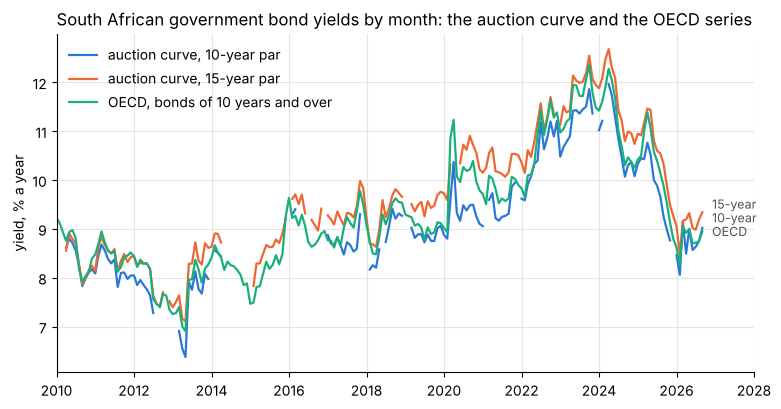

In [20]:
months = pd.date_range("2010-01-01", "2026-09-01", freq="MS").date
par10 = inside[inside.tenor == 10.0].groupby("month").par_yield.mean().reindex(months)
par15 = inside[inside.tenor == 15.0].groupby("month").par_yield.mean().reindex(months)
SA_SERIES = [(par10, "#2a78d6", "auction curve, 10-year par"), (par15, "#eb6834", "auction curve, 15-year par"),
             (oecd.reindex(months), "#1baf7a", "OECD, bonds of 10 years and over")]
fig, ax = plt.subplots(figsize=(9, 4.4))
x = pd.to_datetime(pd.Series(months))
for s, colour, label in SA_SERIES:
    ax.plot(x, s.values, color=colour, lw=1.6, label=label)
ends, gap = {}, 0.28  # direct labels at the last month, nudged apart where the lines meet
for s, colour, label in sorted(SA_SERIES, key=lambda t: t[0].dropna().iloc[-1]):
    ends[label] = max(s.dropna().iloc[-1], max(ends.values(), default=-1e9) + gap)
for s, colour, label in SA_SERIES:
    short = {"auction curve, 10-year par": "10-year", "auction curve, 15-year par": "15-year"}.get(label, "OECD")
    ax.annotate(short, (pd.Timestamp(s.dropna().index[-1]), s.dropna().iloc[-1]), xytext=(pd.Timestamp("2026-12-01"), ends[label]),
                textcoords="data", va="center", fontsize=9, color="#52514e")
ax.set_ylabel("yield, % a year")
ax.set_title("South African government bond yields by month: the auction curve and the OECD series", loc="left")
ax.grid(color="#e6e5e1", lw=0.8); ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(pd.Timestamp("2010-01-01"), pd.Timestamp("2028-01-01"))
ax.legend(frameon=False, loc="upper left")
plt.show()

The OECD series, the Reserve Bank's yield on bonds of 10 years and over, runs between the auction
curve's 10- and 15-year points, and gaps in the two auction lines are months in which no auction
had bonds on both sides of that tenor. 2020 is the widest: the curve was at its steepest from 10 to
15 years, and its 10-year point fell furthest below a series that averages longer bonds.